# Bank Transaction Clustering

Eksplorasi transaksi bank, preprocessing, segmentasi K-Means, dan interpretasi cluster. Target yang dihasilkan merupakan pseudo-label untuk eksperimen klasifikasi berikutnya. Dataset tidak memiliki label fraud asli.

## Library dan direktori proyek

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib

from pathlib import Path

PROJECT_ROOT = next(
    directory for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "data" / "raw" / "bank_transactions.csv").is_file()
)
ARTIFACTS = PROJECT_ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)


## Data transaksi

Dataset lokal berisi 2.537 baris dan 16 kolom. Lima fitur numerik menggambarkan nilai transaksi, usia, durasi, upaya login, dan saldo. Fitur lain mencakup tipe transaksi, lokasi, kanal, pekerjaan, identifier, dan waktu. Provenance dataset tercantum pada README.

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "bank_transactions.csv")

In [3]:
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [5]:
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


In [6]:
numerical_cols = df.select_dtypes(include=['number']).columns

## Exploratory data analysis

Heatmap menunjukkan hubungan linear antarfaktor numerik. Histogram dan distribusi kategori melengkapi ringkasan statistik. Identifier ditampilkan sebagai distribusi frekuensi kemunculan, sedangkan tanggal diringkas sebagai histogram waktu.

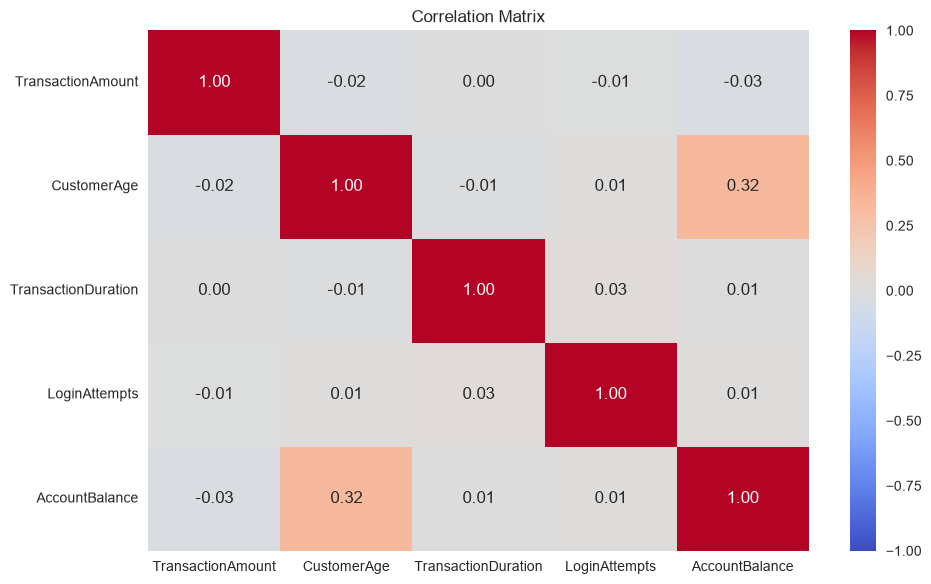

In [7]:
correlation = df[numerical_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

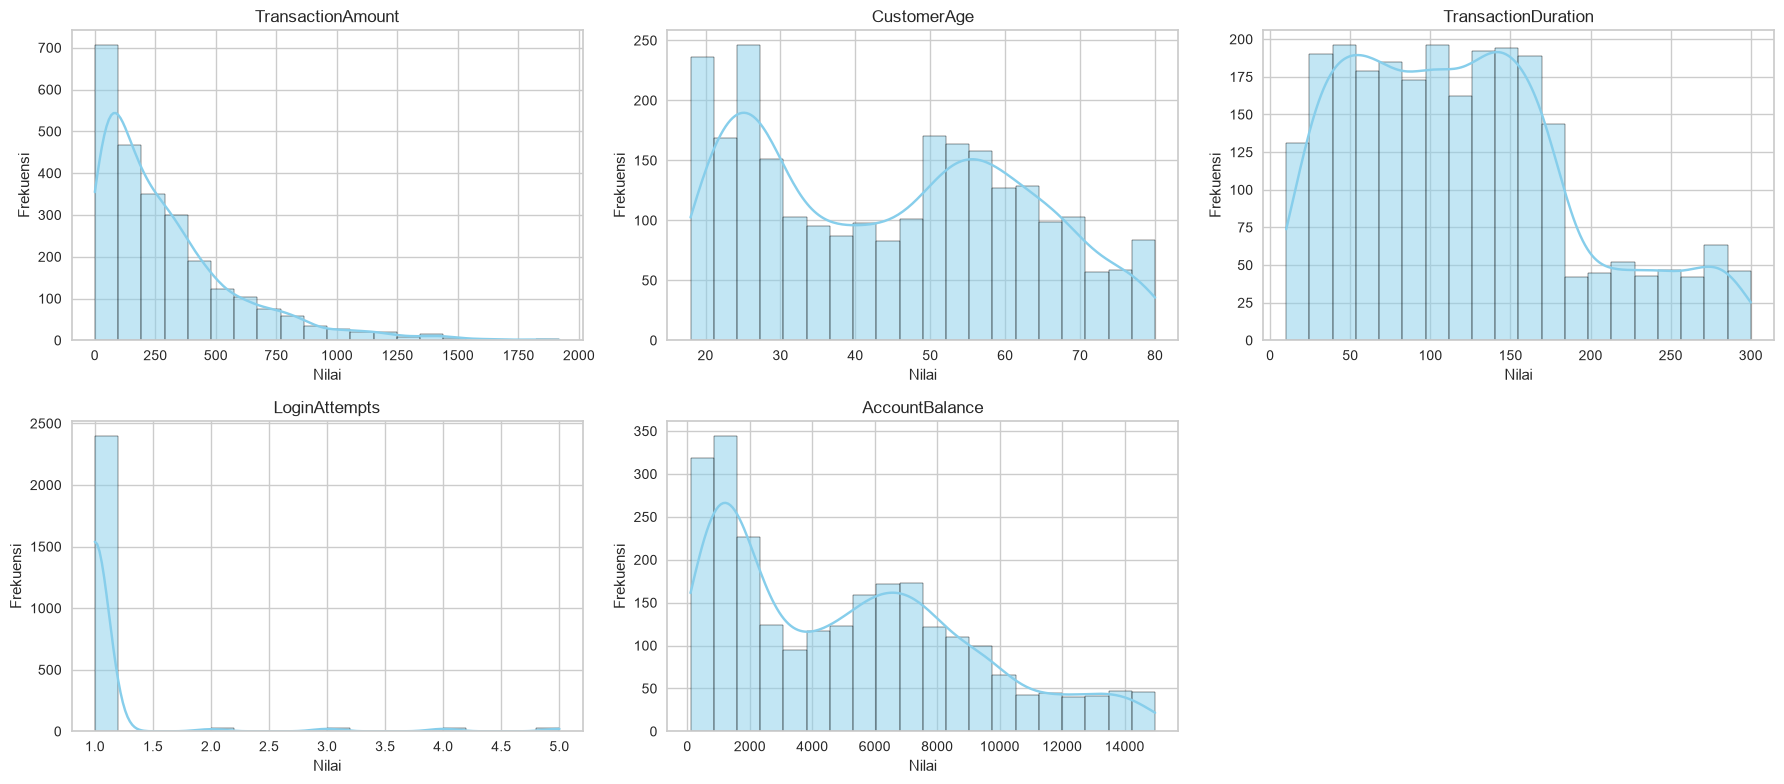

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):

    sns.histplot(df[column], bins=20, kde=True, color='skyblue', ax=axes[i])

    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

for ax in axes[len(numerical_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

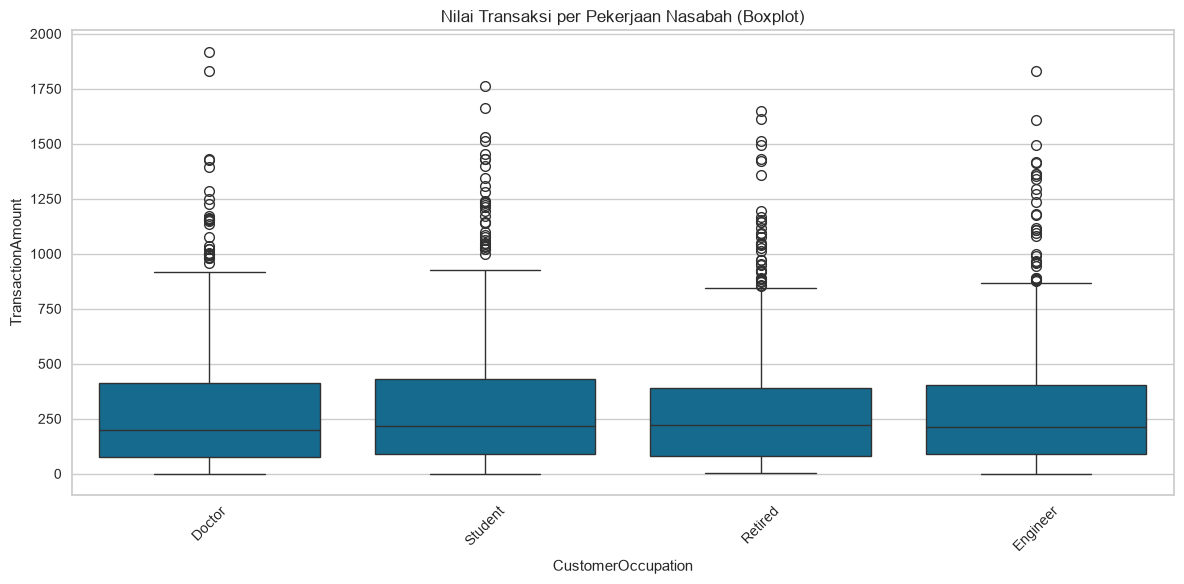

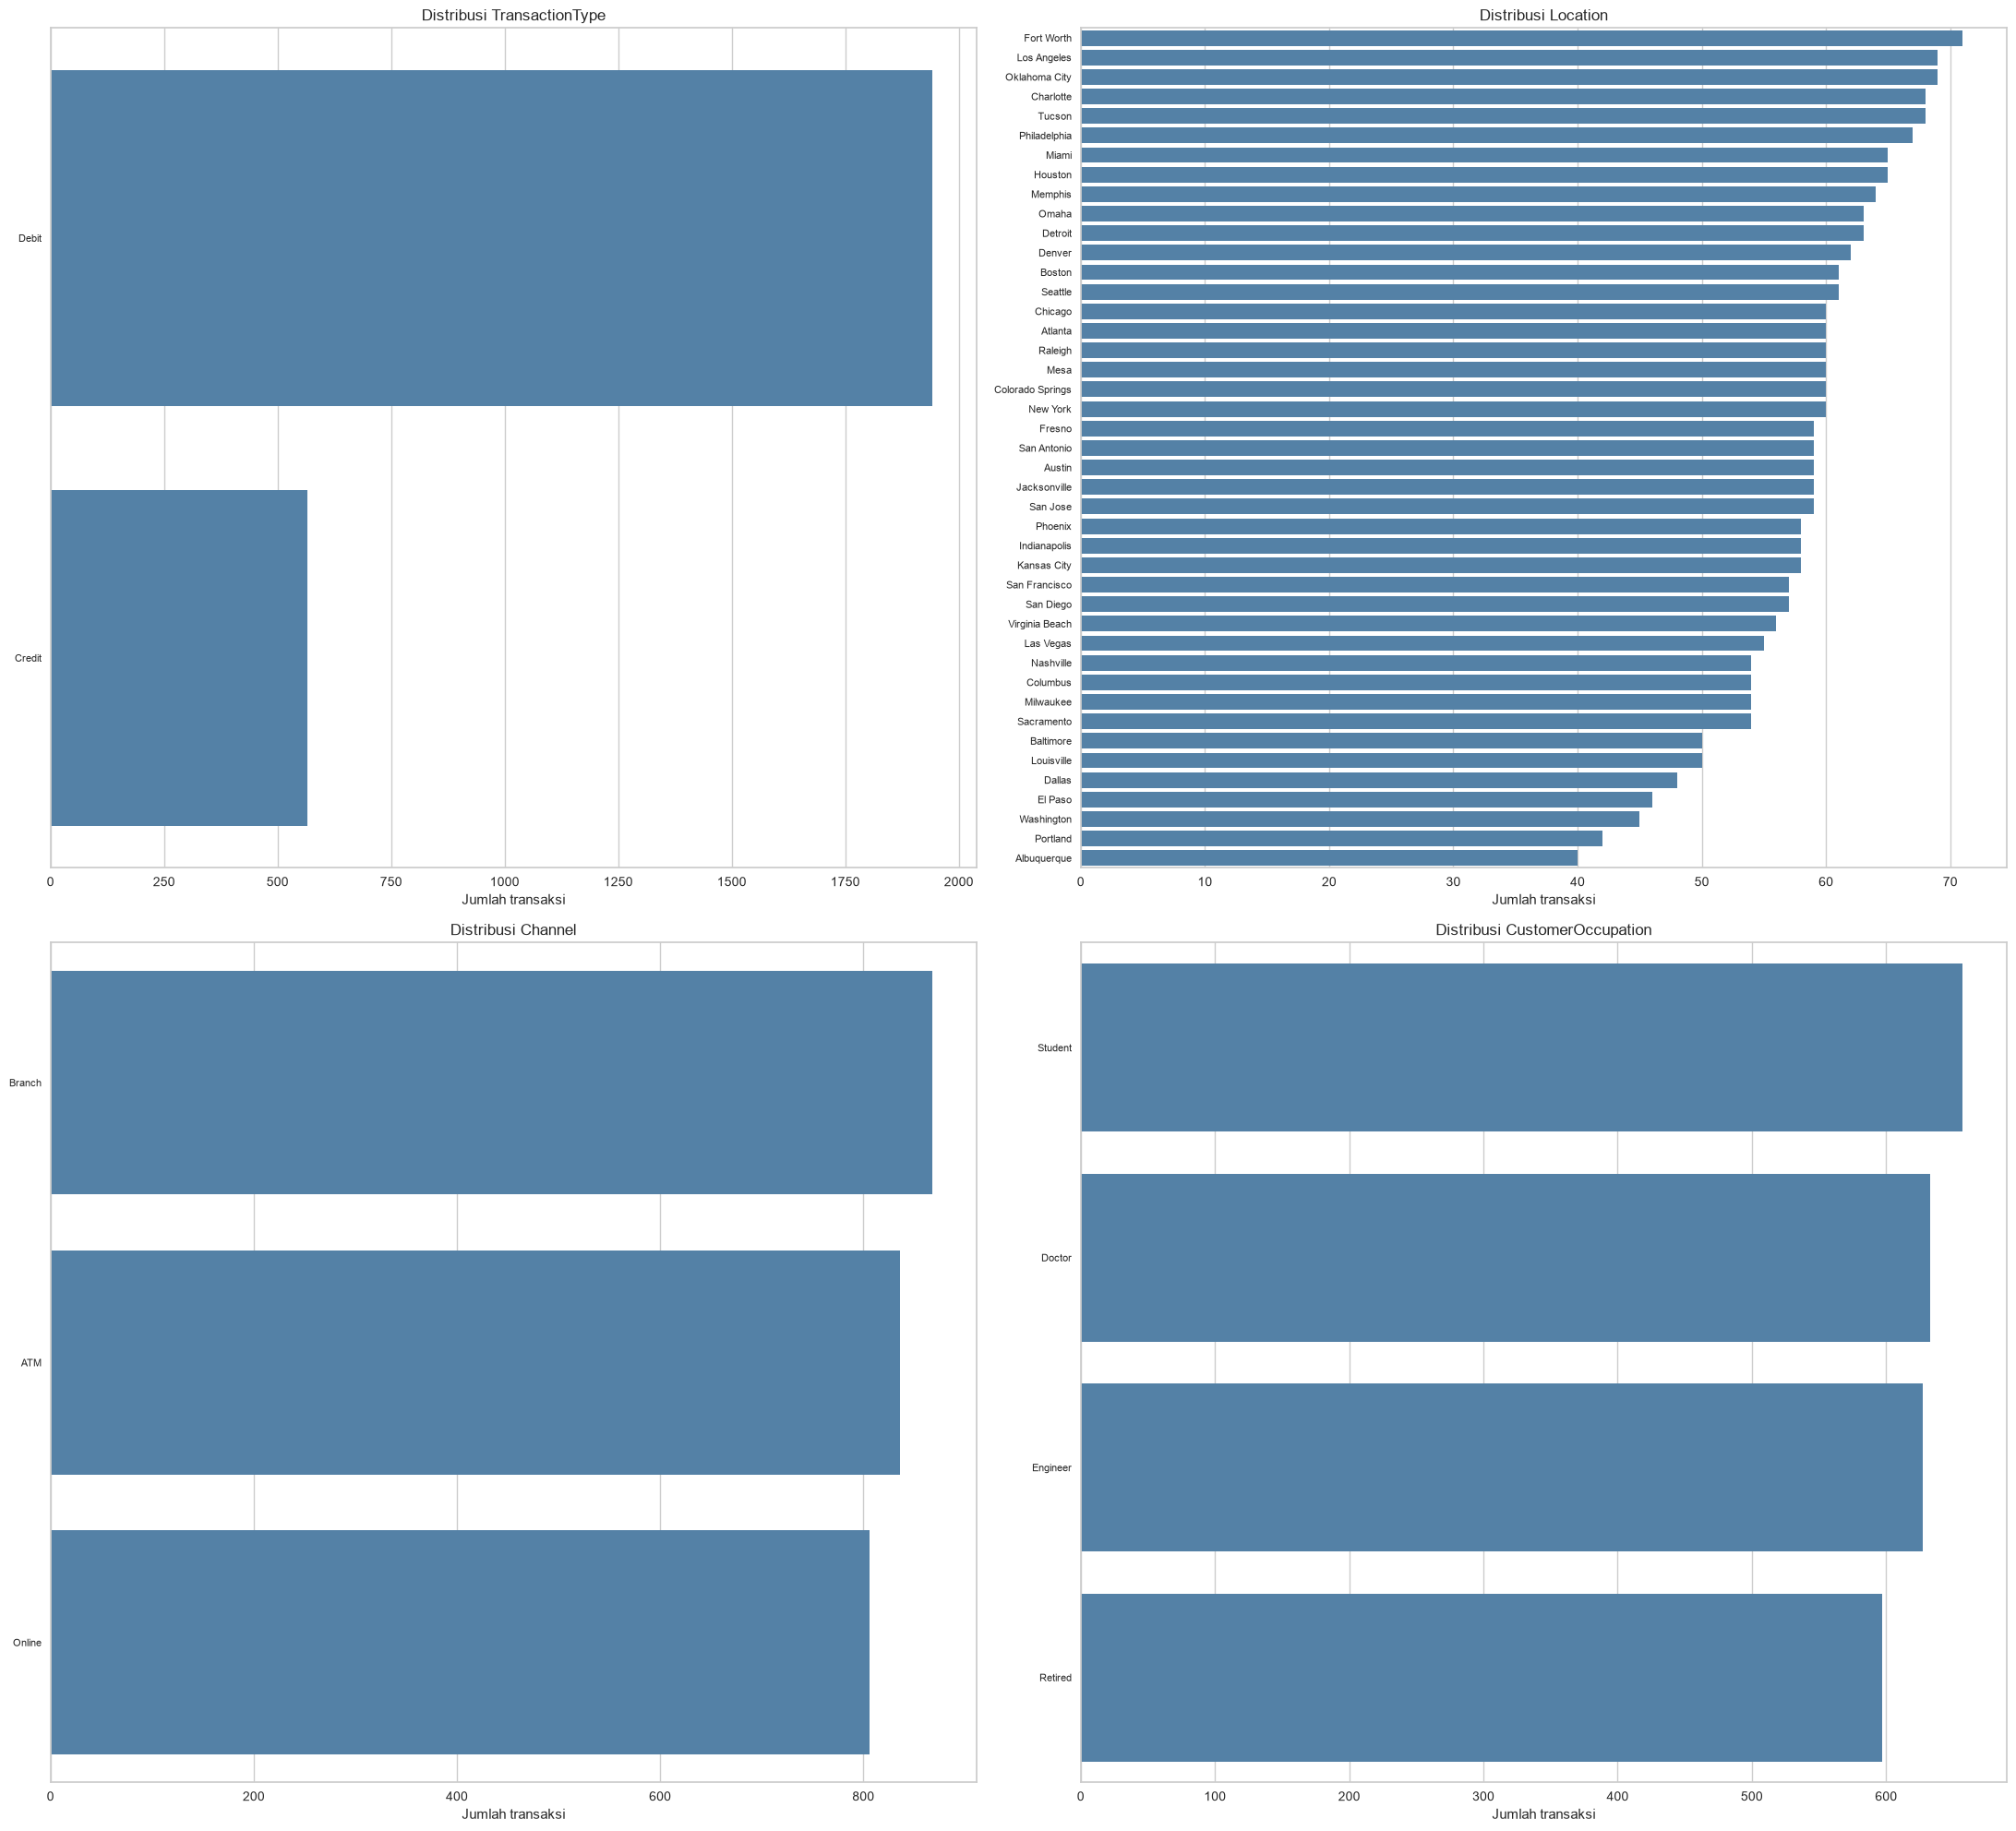

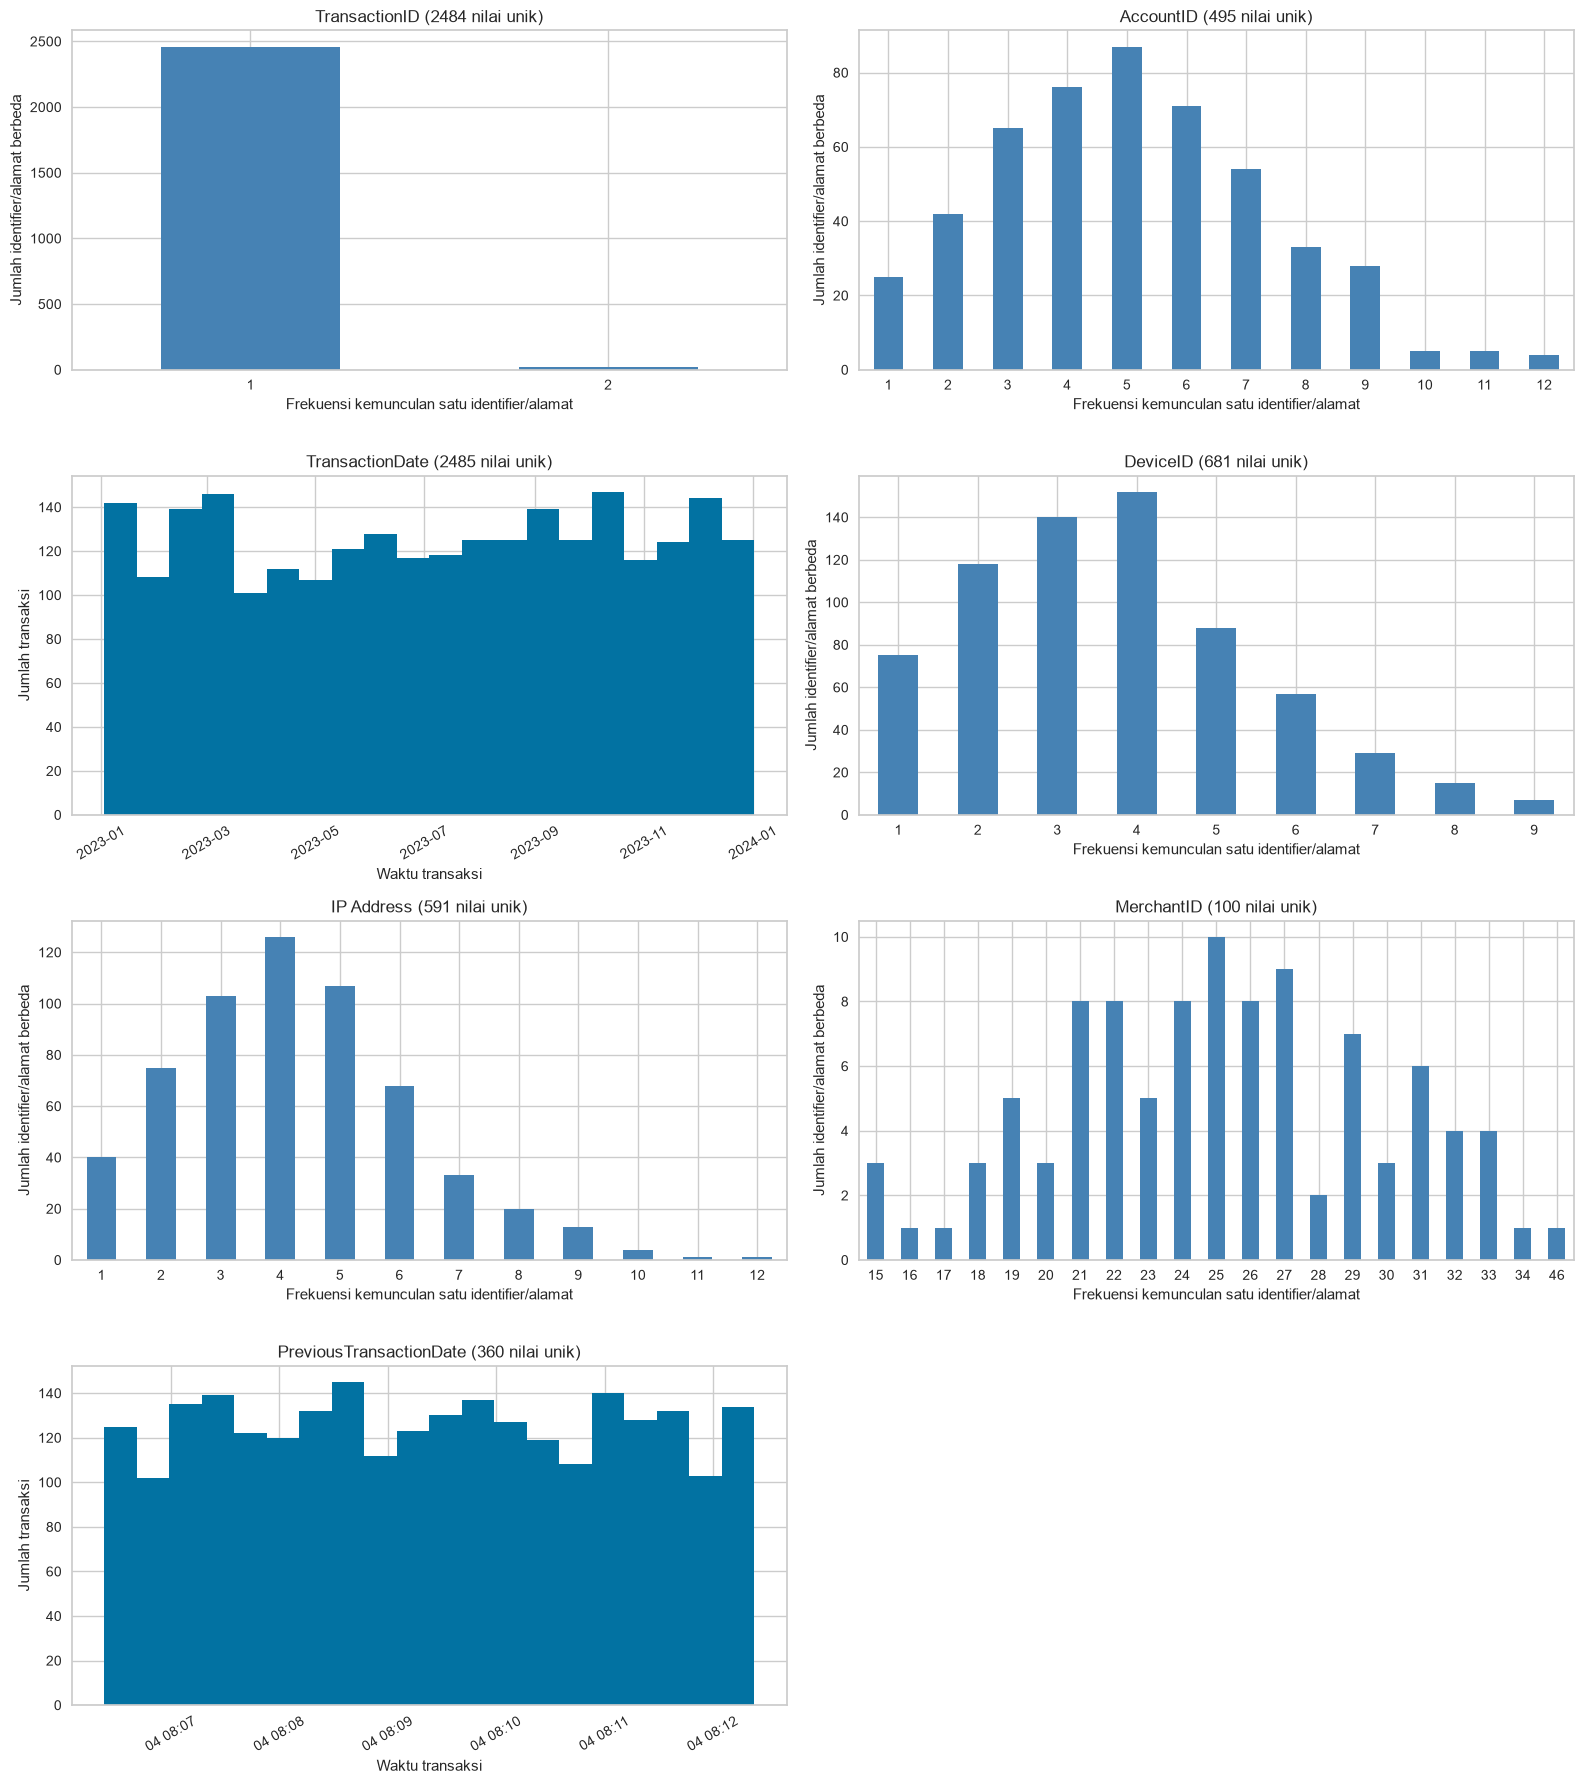

In [9]:
plt.figure(figsize=(12, 6))

sns.boxplot(x='CustomerOccupation', y='TransactionAmount', data=df)

plt.title("Nilai Transaksi per Pekerjaan Nasabah (Boxplot)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

fig, axes_cat = plt.subplots(2, 2, figsize=(22, 20))
for ax, column in zip(axes_cat.flat, ['TransactionType', 'Location', 'Channel', 'CustomerOccupation']):
    sns.countplot(data=df, y=column, order=df[column].value_counts().index,
                  ax=ax, color='steelblue')
    ax.set_title(f'Distribusi {column}', fontsize=12)
    ax.set_ylabel('')
    ax.set_xlabel('Jumlah transaksi')
    ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

summary_cols = [c for c in df.select_dtypes(include='object').columns
                if any(token in c.lower() for token in ['id', 'ip', 'date'])]
fig, axes_summary = plt.subplots(4, 2, figsize=(16, 18))
for ax, column in zip(axes_summary.flat, summary_cols):
    if 'date' in column.lower():
        dates = pd.to_datetime(df[column], errors='raise')
        dates.hist(ax=ax, bins=20)
        ax.set_xlabel('Waktu transaksi')
        ax.tick_params(axis='x', rotation=30)
        ax.set_ylabel('Jumlah transaksi')
    else:
        counts = df[column].value_counts()
        counts.value_counts().sort_index().plot.bar(ax=ax, color='steelblue', rot=0)
        ax.set_xlabel('Frekuensi kemunculan satu identifier/alamat')
        ax.set_ylabel('Jumlah identifier/alamat berbeda')
    ax.set_title(f'{column} ({df[column].nunique()} nilai unik)')
for ax in axes_summary.flat[len(summary_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## Cleaning dan preprocessing

Hapus missing values dan duplikat, lalu keluarkan identifier, alamat IP, dan tanggal dari fitur model. Kategori dikodekan menggunakan LabelEncoder; lima numerik asli dibersihkan dengan IQR berurutan dan distandardisasi. Kuantil usia menjadi fitur tambahan AgeGroup.

In [10]:
df.isnull().sum()

TransactionID              29
AccountID                  21
TransactionAmount          26
TransactionDate            28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
PreviousTransactionDate    24
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(21)

In [12]:
df.dropna(inplace=True)

df.isnull().sum()

TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
dtype: int64

In [13]:
df.drop_duplicates(inplace=True)

df.duplicated().sum()

np.int64(0)

In [14]:
cols_to_drop = [col for col in df.columns if
                'id' in col.lower() or
                'ip' in col.lower() or
                'date' in col.lower()]

df = df.drop(columns=cols_to_drop)

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68


In [15]:
categorical_cols = list(df.select_dtypes(include=['object']).columns)

encoders = {}

for column in categorical_cols:

    label_encoder = LabelEncoder()

    df[column] = label_encoder.fit_transform(df[column])

    encoders[column] = label_encoder

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68


In [16]:
df.columns.tolist()

['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance']

In [17]:
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

df.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
count,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.0,1945.000000
mean,256.838278,0.771722,21.299743,0.977378,44.693059,1.503342,119.225193,1.0,5100.811913
std,218.370197,0.419830,12.329250,0.804119,17.743453,1.135888,70.600647,0.0,3907.153333
min,0.260000,0.000000,0.000000,0.000000,18.000000,0.000000,10.000000,1.0,102.200000
25%,78.920000,1.000000,11.000000,0.000000,27.000000,0.000000,63.000000,1.0,1488.650000
50%,199.700000,1.000000,21.000000,1.000000,45.000000,1.000000,111.000000,1.0,4693.600000
75%,374.500000,1.000000,32.000000,2.000000,59.000000,3.000000,162.000000,1.0,7659.990000
max,903.190000,1.000000,42.000000,2.000000,80.000000,3.000000,300.000000,1.0,14977.990000


In [18]:
scaler = StandardScaler()

df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726


In [19]:
col_to_bin = 'CustomerAge'

new_col_name = 'AgeGroup'

bin_labels = ['Rendah', 'Sedang', 'Tinggi']

df[new_col_name], age_edges = pd.qcut(df[col_to_bin], q=3, labels=bin_labels, retbins=True)

age_edges_original = age_edges * scaler.scale_[list(numerical_cols).index(col_to_bin)] + scaler.mean_[list(numerical_cols).index(col_to_bin)]
print('Batas kuantil usia (tahun):', age_edges_original)

label_encoder = LabelEncoder()
df[new_col_name] = label_encoder.fit_transform(df[new_col_name])

encoders[new_col_name] = label_encoder
categorical_cols.extend([new_col_name])

df.head()

Batas kuantil usia (tahun): [18. 32. 55. 80.]


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,2
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,2
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,0
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,0
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,0


## Pemilihan jumlah cluster dan K-Means

Bandingkan inertia melalui elbow dan silhouette pada K=2..9. Pilih K dengan silhouette tertinggi, kemudian fit model utama pada fitur hasil preprocessing.

In [20]:
df_used = df.copy()

df_used.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup
count,1.945000e+03,1945.000000,1945.000000,1945.000000,1.945000e+03,1945.000000,1.945000e+03,1945.0,1.945000e+03,1945.000000
mean,-8.402305e-17,0.771722,21.299743,0.977378,-1.269479e-16,1.503342,2.557223e-17,0.0,-6.027740e-17,0.983548
std,1.000257e+00,0.419830,12.329250,0.804119,1.000257e+00,1.135888,1.000257e+00,0.0,1.000257e+00,0.819475
min,-1.175271e+00,0.000000,0.000000,0.000000,-1.504776e+00,0.000000,-1.547483e+00,0.0,-1.279678e+00,0.000000
25%,-8.149648e-01,1.000000,11.000000,0.000000,-9.974163e-01,0.000000,-7.965883e-01,0.0,-9.247374e-01,0.000000
50%,-2.617251e-01,1.000000,21.000000,1.000000,1.730327e-02,1.000000,-1.165330e-01,0.0,-1.042490e-01,1.000000
75%,5.389562e-01,1.000000,32.000000,2.000000,8.065296e-01,3.000000,6.060257e-01,0.0,6.551666e-01,2.000000
max,2.960651e+00,1.000000,42.000000,2.000000,1.990369e+00,3.000000,2.561185e+00,0.0,2.528623e+00,2.000000


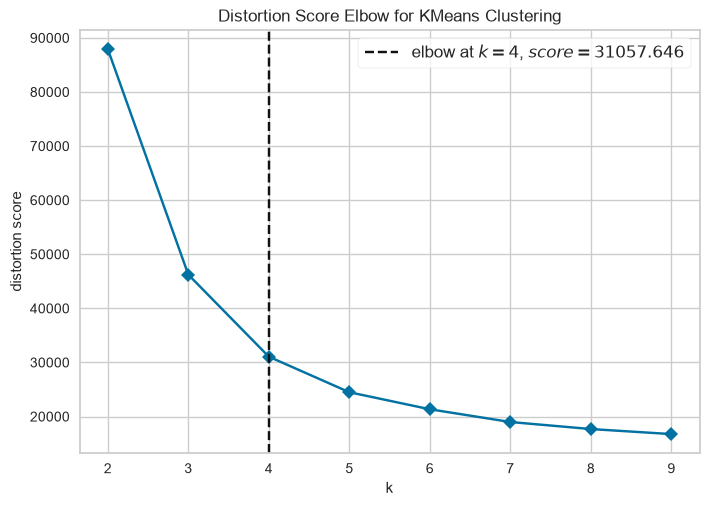

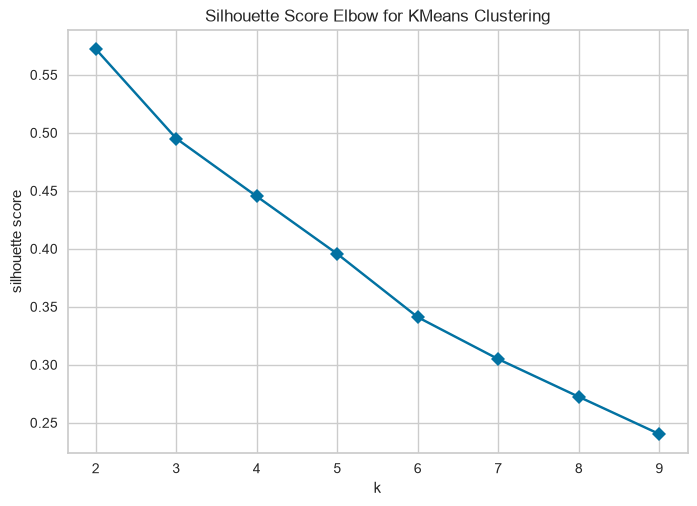

K dengan silhouette tertinggi: 2


,k,silhouette
0,2,0.572160
1,3,0.495036
2,4,0.445118
3,5,0.395524
4,6,0.340946
5,7,0.304800
6,8,0.272306
7,9,0.240195


In [21]:
model = KMeans(random_state=42, n_init=10)

visualizer_elbow = KElbowVisualizer(model, k=(2, 10), metric='distortion', timings=False)
visualizer_elbow.fit(df_used)
visualizer_elbow.show()
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10),
                            k=(2, 10), metric='silhouette', timings=False,
                            locate_elbow=False)
visualizer.fit(df_used)
visualizer.show()
k_scores = pd.DataFrame({'k': visualizer.k_values_, 'silhouette': visualizer.k_scores_})
selected_k = int(k_scores.loc[k_scores['silhouette'].idxmax(), 'k'])
print('K dengan silhouette tertinggi:', selected_k)
k_scores

In [22]:
model = KMeans(n_clusters=selected_k, random_state=42, n_init=10)

model.fit(df)

,n_clusters,2
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [23]:
_ = joblib.dump(model, ARTIFACTS / 'kmeans.joblib')
print("Saved model: artifacts/kmeans.joblib")

Saved model: artifacts/kmeans.joblib


In [24]:
labels = model.labels_

score = silhouette_score(df, labels)

print("Silhouette Score:", score)

Silhouette Score:

 0.572159925838334


## Proyeksi PCA

Plot pertama memproyeksikan label model utama ke dua komponen PCA. Model K-Means terpisah dilatih pada proyeksi dua dimensi sebagai pembanding.

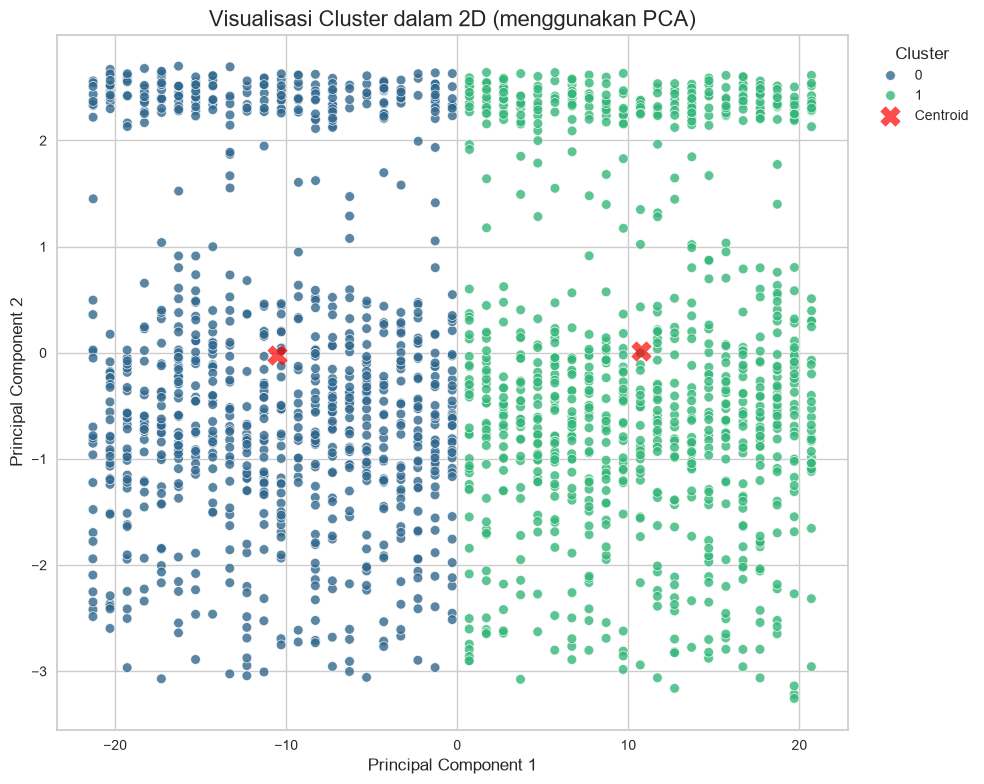

In [25]:
pca = PCA(n_components=2)

df_pca = pca.fit_transform(df)

df_pca = pd.DataFrame(data=df_pca, columns=['Principal Component 1', 'Principal Component 2'])

df_pca['Cluster'] = labels

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',
    palette=sns.color_palette("viridis", n_colors=selected_k),
    data=df_pca,
    legend="full",
    alpha=0.8
)

plt.title('Visualisasi Cluster dalam 2D (menggunakan PCA)', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
centers = pca.transform(pd.DataFrame(model.cluster_centers_, columns=df.columns))
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.7, marker='X', label='Centroid')
plt.legend(title="Cluster", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [26]:
pca = PCA(n_components=2)

df_pca_array = pca.fit_transform(df_used)

data_final = pd.DataFrame(data=df_pca_array, columns=['PCA1', 'PCA2'])

kmeans_pca = KMeans(n_clusters=selected_k, random_state=42, n_init=10)

kmeans_pca.fit(data_final)

,n_clusters,2
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [27]:
_ = joblib.dump(kmeans_pca, ARTIFACTS / 'kmeans_pca.joblib')
print("Saved model: artifacts/kmeans_pca.joblib")

Saved model: artifacts/kmeans_pca.joblib


## Profil cluster

Ringkasan berikut memakai skala fitur hasil preprocessing; label belum ditambahkan sebagai fitur pelatihan.

In [28]:
df_used['Cluster'] = labels

agg_summary = df_used.groupby('Cluster')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

display(agg_summary)

Cluster                      0     1
TransactionAmount   mean -0.01  0.01
                    min  -1.17 -1.18
                    max   2.96  2.90
CustomerAge         mean  0.02 -0.02
                    min  -1.50 -1.50
                    max   1.99  1.99
TransactionDuration mean  0.03 -0.03
                    min  -1.55 -1.55
                    max   2.56  2.55
LoginAttempts       mean  0.00  0.00
                    min   0.00  0.00
                    max   0.00  0.00
AccountBalance      mean  0.01 -0.01
                    min  -1.28 -1.28
                    max   2.52  2.53

### Karakteristik pada skala preprocessing

1. **CLUSTER 0: Nasabah di kelompok lokasi A–L (980 transaksi)**
   - **TransactionAmount:** mean **-0,01** (setelah inverse: **255,55**), min **-1,17**, max **2,96**.
   - **CustomerAge:** mean **0,02** (setelah inverse: **45,06 tahun**), min **-1,50**, max **1,99**.
   - **TransactionDuration:** mean **0,03** (setelah inverse: **121,12**), min **-1,55**, max **2,56**.
   - **AccountBalance:** mean **0,01** (setelah inverse: **5.142,17**), min **-1,28**, max **2,52**.
   - **Analisis:** Memiliki nilai saldo dan durasi transaksi sedikit di atas rerata. Dominasi utama clustering justru datang dari kode fitur `Location` hasil LabelEncoder: lokasi dalam kelompok ini berada pada urutan nama alfabet **Albuquerque** hingga **Louisville**. Pengelompokan ini bukan bukti transaksi fraud.

2. **CLUSTER 1: Nasabah di kelompok lokasi M–W (965 transaksi)**
   - **TransactionAmount:** mean **0,01** (setelah inverse: **258,15**), min **-1,18**, max **2,90**.
   - **CustomerAge:** mean **-0,02** (setelah inverse: **44,33 tahun**), min **-1,50**, max **1,99**.
   - **TransactionDuration:** mean **-0,03** (setelah inverse: **117,30**), min **-1,55**, max **2,55**.
   - **AccountBalance:** mean **-0,01** (setelah inverse: **5.058,81**), min **-1,28**, max **2,53**.
   - **Analisis:** Besaran transaksi sedikit lebih tinggi, tetapi saldo dan durasi sedikit lebih rendah daripada Cluster 0. Lokasi dalam kelompok ini terbentang dari **Memphis** hingga **Washington**. Perbedaan indikator keuangan relatif kecil, sehingga persona cluster dibatasi sebagai pengelompokan berdasarkan representasi lokasi.

**Catatan metodologi:** `Location` diubah dengan `LabelEncoder`, sehingga nilai kategorinya bersifat ordinal secara artifisial. Jarak Euclidean K-Means menjadi sangat dipengaruhi kode lokasi. Silhouette Score menjelaskan keterpisahan hasil clustering, **bukan** akurasi identifikasi penipuan transaksi. Penghapusan outlier juga menjadikan `LoginAttempts` konstan (=1) pada data akhir.

**Pemilihan K:** Elbow distortion Yellowbrick mendeteksi siku pada **K=4**, sedangkan silhouette pada K=2..9 mencapai maksimum **0,572160 pada K=2** (K=3: 0,495036; K=4: 0,445118). Model utama memakai K=2 berdasarkan pemisahan relatif yang lebih kuat dan segmentasi yang lebih sederhana. Siku distortion menunjukkan kompromi penurunan inertia, sehingga tidak harus sama dengan maksimum silhouette. Silhouette ini berlaku pada representasi encoding yang digunakan, bukan jaminan segmentasi geografis yang bermakna.

**Binning dan seleksi data:** AgeGroup berasal dari kuantil usia dengan batas asli **18, 32, 55, 80 tahun**: Rendah [18,32], Sedang (32,55], Tinggi (55,80]. StandardScaler mempertahankan urutan sehingga qcut sesudah scaling menghasilkan pembagian yang sama. IQR diterapkan berurutan pada lima fitur numerik asli; LoginAttempts memiliki IQR nol sehingga nilai di atas 1 terhapus. Pembuangan nilai ekstrem/missing membatasi populasi analisis dan justru dapat membuang calon anomali; tidak digunakan untuk menyimpulkan fraud.


## Ekspor dan inverse transformation

Target menyimpan pseudo-label K-Means. Kembalikan fitur numerik dan kategorikal ke satuan aslinya untuk interpretasi dan klasifikasi. Kedua CSV disimpan dalam artifacts/ dan dapat dibuat ulang.

In [29]:
df_used.rename(columns={"Cluster": "Target"}, inplace=True)

df_used.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,2,1
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,2,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,0,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,0,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,0,1


In [30]:
df_used.to_csv(ARTIFACTS / 'clustered_transactions.csv', index=False)

In [31]:
df_inverse = df_used.copy()

df_inverse[numerical_cols] = scaler.inverse_transform(df_inverse[numerical_cols])

df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21,2,1
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91,2,0
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35,0,1
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06,0,1
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68,0,1


In [32]:
for column in categorical_cols:

    encoder = encoders[column]

    df_inverse[column] = encoder.inverse_transform(df_inverse[column].astype(int))

df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Tinggi,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Tinggi,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Rendah,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Rendah,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Rendah,1


In [33]:
agg_summary_num = df_inverse.groupby('Target')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

agg_summary_cat = df_inverse.groupby('Target')[categorical_cols].agg(lambda x: x.mode()[0]).round(2).T

display(agg_summary_num)
display(agg_summary_cat)

Target                           0         1
TransactionAmount   mean    255.55    258.15
                    min       0.32      0.26
                    max     903.19    889.01
CustomerAge         mean     45.06     44.33
                    min      18.00     18.00
                    max      80.00     80.00
TransactionDuration mean    121.12    117.30
                    min      10.00     10.00
                    max     300.00    299.00
LoginAttempts       mean      1.00      1.00
                    min       1.00      1.00
                    max       1.00      1.00
AccountBalance      mean   5142.17   5058.81
                    min     117.98    102.20
                    max   14942.78  14977.99

Target,0,1
TransactionType,Debit,Debit
Location,Charlotte,Tucson
Channel,Branch,Branch
CustomerOccupation,Doctor,Student
AgeGroup,Sedang,Rendah


### Karakteristik pada satuan asli

1. **Cluster 0 — Kelompok lokasi A–L (980 transaksi)**
   - **TransactionAmount:** mean **255,55**, min **0,32**, max **903,19**.
   - **CustomerAge:** mean **45,06**, min **18**, max **80**.
   - **TransactionDuration:** mean **121,12**, min **10**, max **300**.
   - **AccountBalance:** mean **5.142,17**, min **117,98**, max **14.942,78**.
   - **Fitur kategorikal yang paling sering (mode):** `TransactionType=Debit`, `Location=Charlotte`, `Channel=Branch`, `CustomerOccupation=Doctor`, `AgeGroup=Sedang`.
   - **Analisis:** Terdiri dari lokasi berurutan alfabet A–L; jumlah transaksi dan saldo rata-rata secara umum mirip dengan Cluster 1. Durasi transaksi dan saldo sedikit lebih besar.

2. **Cluster 1 — Kelompok lokasi M–W (965 transaksi)**
   - **TransactionAmount:** mean **258,15**, min **0,26**, max **889,01**.
   - **CustomerAge:** mean **44,33**, min **18**, max **80**.
   - **TransactionDuration:** mean **117,30**, min **10**, max **299**.
   - **AccountBalance:** mean **5.058,81**, min **102,20**, max **14.977,99**.
   - **Fitur kategorikal yang paling sering (mode):** `TransactionType=Debit`, `Location=Tucson`, `Channel=Branch`, `CustomerOccupation=Student`, `AgeGroup=Rendah`.
   - **Analisis:** Terdiri dari lokasi berurutan alfabet M–W. Rata-rata nilai transaksi lebih tinggi sekitar **2,60**, tetapi durasi sekitar **3,82** lebih singkat dan saldo rata-rata sekitar **83,36** lebih rendah dibandingkan Cluster 0.

**Kesimpulan:** Data inverse membantu mengartikan skala angka dan kategori ke bentuk semula. Pengelompokan yang dihasilkan terutama memisahkan kelompok kode `Location`, sehingga hasil tersebut sebaiknya digunakan sebagai label pseudo-supervised untuk tugas klasifikasi, bukan sebagai pelabelan fraud yang telah diverifikasi.

In [34]:
df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Tinggi,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Tinggi,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Rendah,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Rendah,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Rendah,1


In [35]:
assert not df_inverse.isna().any().any()
assert df_used['Target'].equals(df_inverse['Target'])
assert np.allclose(scaler.transform(df_inverse[numerical_cols]), df_used[numerical_cols])
for column in categorical_cols:
    assert np.array_equal(encoders[column].transform(df_inverse[column]), df_used[column])
df_inverse.to_csv(ARTIFACTS / 'clustered_transactions_inverse.csv', index=False)
print('Ekspor dan round-trip inverse valid:', df_inverse.shape)
print(df_inverse['Target'].value_counts().sort_index())

Ekspor dan round-trip inverse valid: (1945, 11)
Target
0    980
1    965
Name: count, dtype: int64
